In [1]:
#Cell 1: load and split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

SEED = 42

# No Kaggle account needed; this is the same Ames data (1460 rows)
raw = fetch_openml(name="house_prices", as_frame=True, parser="auto").frame
raw.to_csv("../data/ames_raw.csv", index=False)

# Drop the Id column if present
raw = raw.drop(columns=["Id"], errors="ignore")

X = raw.drop(columns=["SalePrice"])
y = raw["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print(X_train.shape, X_test.shape)

# Save the test set and don't look at it again
X_test.assign(SalePrice=y_test).to_csv("../data/test_holdout.csv", index=False)

(1168, 79) (292, 79)


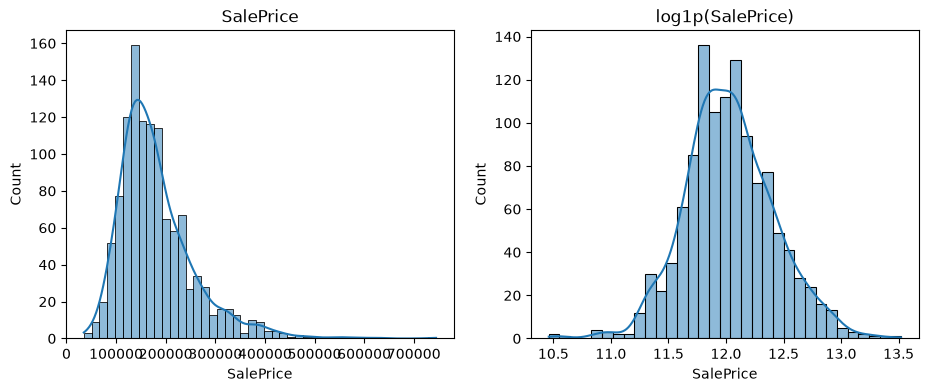

Skew raw: 1.743128561420854 | Skew log: 0.12489024367918913


In [2]:
#Cell 2: target distribution (training data only)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(y_train, kde=True, ax=ax[0]); ax[0].set_title("SalePrice")
sns.histplot(np.log1p(y_train), kde=True, ax=ax[1]); ax[1].set_title("log1p(SalePrice)")
plt.show()
print("Skew raw:", y_train.skew(), "| Skew log:", np.log1p(y_train).skew())

In [ ]:
#Cell 3: missing values and types
train = X_train.copy()
missing = train.isna().sum().sort_values(ascending=False)
print(missing[missing > 0])
print(train.dtypes.value_counts())



# 1. Find columns with missing values and count them with their data type 
#missing_count = X_train.isna().sum()
#missing_count = missing_count[missing_count > 0]

# 2. Grab their data types and combine them into a neat summary table
#missing_summary = pd.DataFrame({
#    'Missing_Rows': missing_count,
#    'Data_Type': X_train[missing_count.index].dtypes
#})

# 3. Sort from highest missing rows to lowest and print
#print(missing_summary.sort_values(by='Missing_Rows', ascending=False))

PoolQC          1162
MiscFeature     1122
Alley           1094
Fence            935
FireplaceQu      547
LotFrontage      217
GarageYrBlt       64
GarageQual        64
GarageFinish      64
GarageType        64
GarageCond        64
BsmtQual          28
BsmtFinType1      28
BsmtCond          28
BsmtFinType2      28
BsmtExposure      28
MasVnrType         6
MasVnrArea         6
Electrical         1
dtype: int64
str        43
int64      33
float64     3
Name: count, dtype: int64


OverallQual     0.807946
GrLivArea       0.689012
GarageCars      0.684451
GarageArea      0.654520
TotalBsmtSF     0.597214
FullBath        0.583747
1stFlrSF        0.580948
YearBuilt       0.576725
YearRemodAdd    0.562152
GarageYrBlt     0.530321
TotRmsAbvGrd    0.520082
Fireplaces      0.481761
MasVnrArea      0.422218
BsmtFinSF1      0.340878
WoodDeckSF      0.340702
Name: LogPrice, dtype: float64


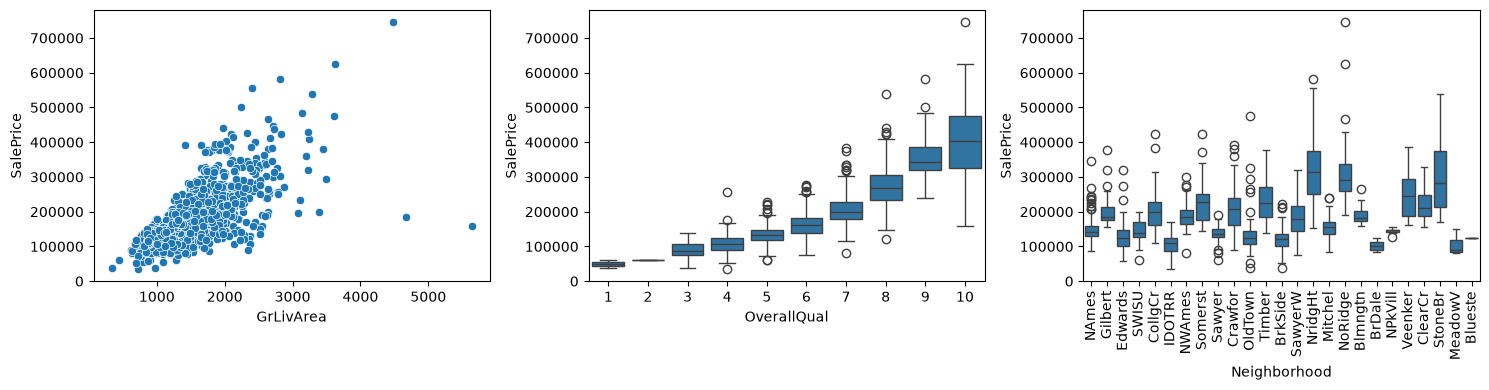

In [4]:
#Cell 4: what drives price
num = train.select_dtypes("number").assign(LogPrice=np.log1p(y_train))
corr = num.corr()["LogPrice"].drop("LogPrice").sort_values(key=abs, ascending=False)
print(corr.head(15))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(x=train["GrLivArea"], y=y_train, ax=ax[0])
sns.boxplot(x=train["OverallQual"], y=y_train, ax=ax[1])
sns.boxplot(x=train["Neighborhood"], y=y_train, ax=ax[2]); ax[2].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()